# Module 2 · Partie 4 : La régression PLS (Partial Least Squares)

> *Multivaried Analysis 2 : Data Mining & Machine Learning*, Prof. Hélène Soyeurt, ULiège Gembloux Agro-Bio Tech, 2026-2027
> Sources : syllabus *Validation, PCR and PLS* (`module2.pdf`, chapitre 3), exercice dirigé officiel `PLS_PCR_fatty_acids_20201007.Rmd` (§4), script `pls_fatty_acids.R`.

**Objectifs d'apprentissage**

À la fin de ce notebook, tu sauras :

1. expliquer la différence **conceptuelle** entre PCR et PLS (variance de X seule vs compromis variance de X / covariance avec y) ;
2. dérouler **à la main** l'algorithme **NIPALS** (PLS1) sur l'exemple de l'indice d'octane et retrouver toutes les tables du syllabus (Tables 3 à 8) ;
3. utiliser `plsr()` du package `pls` et faire le lien entre ses sorties (`scores`, `loadings`, `loading.weights`, `projection`, `Yloadings`) et les notations du cours ($t$, $p$, $w$, $w^*$, $c$) ;
4. choisir le **nombre de variables latentes** par validation croisée (RMSEP) et par la statistique **Q²** (Table 9) ;
5. détecter les observations atypiques avec le **T² de Hotelling** (Table 10) et la règle moyenne ± 3 écarts-types des résidus ;
6. interpréter les variables latentes (corrélations, Table 11 ; poids $w^*$, Table 12 ; poids $c$) ;
7. appliquer la PLS aux spectres MIR pour prédire les acides gras saturés (SAT) et la comparer à la PCR.

**Prérequis** : parties 1 (validation croisée), 2 (ACP, distance GH) et 3 (PCR, package `pls`).

**Sommaire**

- 4.0 Préparation
- 4.1 Introduction : de la PCR à la PLS
- 4.2 L'exemple de l'indice d'octane
- 4.3 L'algorithme NIPALS pas à pas
- 4.4 La PLS avec `plsr()`
- 4.5 Combien de variables latentes ? Validation croisée et Q²
- 4.6 Détection des valeurs anormales : T² de Hotelling
- 4.7 Pouvoir prédictif et explicatif des variables latentes
- 4.8 PLS pénalisée et avantages de la PLS
- 4.9 Application : acides gras saturés du lait (exercice dirigé)
- 4.10 PCR vs PLS sur les acides gras
- Questions de compréhension
- Récapitulatif

## 4.0 Préparation

Packages utilisés :

- `pls` : `plsr()`, `pcr()`, `RMSEP()`, `R2()`, `selectNcomp()`… (cf. partie 3) ;
- `FactoMineR` : `PCA()` pour la distance GH (cf. partie 2) ;
- `knitr` : `kable()` pour des tableaux lisibles ;
- `ggplot2` et `reshape2` : uniquement pour reproduire les graphiques de l'exercice dirigé officiel.

In [1]:
suppressPackageStartupMessages({
  library(pls)
  library(FactoMineR)
  library(knitr)
  library(ggplot2)
  library(reshape2)
})
options(repr.plot.width = 10, repr.plot.height = 6)   # taille des figures (spécifique à Jupyter)

> **Attention** : le package `pls` contient une fonction `loadings()` qui **masque** celle du package `stats` (message « The following object is masked from 'package:stats' »). C'est sans conséquence ici : on veut justement celle de `pls`.

---
## 4.1 Introduction : de la PCR à la PLS

Comme la PCR (partie 3), la **régression PLS** (*Partial Least Squares regression*) **réduit la dimension** de la matrice X : au lieu de régresser y sur des centaines de variables colinéaires, on le régresse sur quelques nouvelles variables, combinaisons linéaires des variables d'origine.

La différence est **conceptuelle** (syllabus §3.1) :

| | PCR | PLS |
|---|---|---|
| Nouvelles variables | **composantes principales** (*principal components*) | **variables latentes** (*latent variables*) |
| Critère pour les construire | maximiser la **variance de X** (ACP, non supervisée) | compromis entre **variance de X** et **lien avec y** : maximiser $\mathrm{cov}(T, y)$ |
| y intervient dans la construction ? | **non** (seulement dans la régression finale) | **oui**, dès la 1re variable latente |

> **Définition** : une **variable latente** $t_h$ est une combinaison linéaire des variables explicatives standardisées, construite de façon à **maximiser sa covariance avec y** (et non sa seule variance, comme une composante principale).

Repères historiques et vocabulaire :

- méthode créée en **1983 par Wold et al.** à partir de l'algorithme **NIPALS** (*Non linear Iterative Partial Least Squares*) ;
- très utilisée en **chimiométrie** : spectroscopie, chromatographie, chimie, cosmétique, biologie… ;
- **PLS1** : une seule variable à expliquer (vecteur y) ; **PLS2** : plusieurs variables à expliquer (matrice Y). Dans ce cours, on se concentre sur la **PLS1**.

> **Complément** : on rappelle l'inconvénient principal de la PCR vu en partie 3 : une composante qui explique beaucoup de variance de X peut n'avoir **aucun lien** avec y, et inversement une petite direction de variance peut être très prédictive. La PLS corrige ce défaut en « orientant » la réduction de dimension vers y. C'est pourquoi elle atteint en général la même performance **avec moins de composantes**.

---
## 4.2 L'exemple de l'indice d'octane

Le syllabus illustre toute la méthode sur un petit jeu de données : l'**indice d'octane** (y) de **12 mélanges** de carburant en fonction des proportions de **7 composants** (X1 à X7). C'est le même exemple que pour la PCR (Table 1, partie 3). On le ressaisit pour que le notebook soit autonome.

In [2]:
# Table 1 du syllabus : 12 mélanges, 7 composants, indice d'octane
octane <- data.frame(
  X1 = c(0, 0, 0, 0, 0, 0, 0.17, 0.17, 0.17, 0.17, 0.21, 0),
  X2 = c(0.23, 0.1, 0, 0.49, 0, 0.62, 0.27, 0.19, 0.21, 0.15, 0.36, 0),
  X3 = c(0, 0, 0, 0, 0, 0, 0.1, 0.1, 0.1, 0.1, 0.12, 0),
  X4 = c(0, 0, 0.1, 0, 0.62, 0, 0.38, 0.38, 0.38, 0.38, 0.25, 0.55),
  X5 = c(0, 0.12, 0.12, 0.12, 0.12, 0, 0, 0.02, 0, 0.02, 0, 0),
  X6 = c(0.74, 0.74, 0.74, 0.37, 0.18, 0.37, 0, 0.06, 0.06, 0.1, 0, 0.37),
  X7 = c(0.03, 0.04, 0.04, 0.02, 0.08, 0.01, 0.08, 0.08, 0.08, 0.08, 0.06, 0.08),
  y  = c(98.7, 97.8, 96.6, 92, 86.6, 91.2, 81.9, 83.1, 82.4, 83.2, 81.4, 88.1)
)
X <- as.matrix(octane[, 1:7])   # variables explicatives
y <- octane$y                   # indice d'octane
n <- nrow(X); p <- ncol(X)
c(n = n, p = p)
round(cor(X), 2)                # forte colinéarité : r(X1, X3) = 1.00 !

n  p 
12  7

,X1,X2,X3,X4,X5,X6,X7
X1,1.00,0.10,1.00,0.37,-0.55,-0.80,0.60
X2,0.10,1.00,0.10,-0.54,-0.29,-0.19,-0.59
X3,1.00,0.10,1.00,0.37,-0.55,-0.81,0.61
X4,0.37,-0.54,0.37,1.00,-0.21,-0.65,0.92
X5,-0.55,-0.29,-0.55,-0.21,1.00,0.46,-0.27
X6,-0.80,-0.19,-0.81,-0.65,0.46,1.00,-0.66
X7,0.60,-0.59,0.61,0.92,-0.27,-0.66,1.00


> **Attention** : chaque ligne est un **mélange** dont les proportions somment à 1 (vérifie avec `rowSums(X)`). Une fois les variables centrées, X n'est donc que de **rang 6** et non 7 : une des 7 directions est vide. Cela aura une conséquence visible sur la 7e variable latente (section 4.3.5).

In [3]:
rowSums(X)                      # chaque mélange somme à 1
qr(scale(X))$rank               # rang de X centré-réduit : 6 et non 7

[1] 1 1 1 1 1 1 1 1 1 1 1 1

[1] 6

---
## 4.3 L'algorithme NIPALS pas à pas

La PLS décompose **à la fois** la matrice X et le vecteur y. L'algorithme NIPALS réalise cette double décomposition en trois étapes (syllabus §3.2).

### 4.3.1 Étape 1 : standardisation

On centre et on réduit toutes les variables (moyenne 0, écart-type 1) :

$$y_{s,i} = \frac{y_i - \bar y}{\sigma_y} \qquad\qquad x_{s,ij} = \frac{x_{ij} - \bar x_j}{\sigma_{x_j}}$$

où $j$ désigne une variable explicative.

In [4]:
Xs <- scale(X)                  # centrage-réduction de chaque colonne (écart-type en n-1)
ys <- as.vector(scale(y))
# Table 3 du syllabus
kable(cbind(round(Xs, 3), "Octane indice" = round(ys, 3)), align = "c")



|   X1   |   X2   |   X3   |   X4   |   X5   |   X6   |   X7   | Octane indice |
|:------:|:------:|:------:|:------:|:------:|:------:|:------:|:-------------:|
| -0.804 | 0.060  | -0.805 | -1.116 | -0.759 | 1.465  | -0.985 |     1.551     |
| -0.804 | -0.605 | -0.805 | -1.116 | 1.343  | 1.465  | -0.615 |     1.413     |
| -0.804 | -1.117 | -0.805 | -0.675 | 1.343  | 1.465  | -0.615 |     1.229     |
| -0.804 | 1.389  | -0.805 | -1.116 | 1.343  | 0.202  | -1.354 |     0.524     |
| -0.804 | -1.117 | -0.805 | 1.615  | 1.343  | -0.447 | 0.862  |    -0.304     |
| -0.804 | 2.054  | -0.805 | -1.116 | -0.759 | 0.202  | -1.723 |     0.401     |
| 1.038  | 0.264  | 1.053  | 0.558  | -0.759 | -1.061 | 0.862  |    -1.025     |
| 1.038  | -0.145 | 1.053  | 0.558  | -0.409 | -0.856 | 0.862  |    -0.841     |
| 1.038  | -0.043 | 1.053  | 0.558  | -0.759 | -0.856 | 0.862  |    -0.948     |
| 1.038  | -0.349 | 1.053  | 0.558  | -0.409 | -0.720 | 0.862  |    -0.826     |
| 1.472  | 0.725  | 1.424 

On retrouve exactement la **Table 3** du syllabus (la colonne y y est intitulée par erreur « Octave indice »).

### 4.3.2 Étape 2 : la première variable latente

On cherche la combinaison linéaire de $X_s$ la plus liée à $y_s$. Pour cela, on calcule la **corrélation** entre chaque variable $x_{s_j}$ et $y_s$ (Table 4) :

$$R_{y_s, x_{s_j}} = \frac{\mathrm{cov}(x_{s_j}, y_s)}{\sigma_{x_{s_j}}\,\sigma_{y_s}}$$

Comme les données sont standardisées ($\sigma = 1$), **corrélation et covariance sont égales**.

In [5]:
R <- cor(Xs, ys)                # 7 corrélations (identiques sur X brut ou standardisé)
kable(t(round(R, 3)), align = "c", caption = "Table 4 : corrélations avec l'indice d'octane")
all.equal(as.vector(R), as.vector(cov(Xs, ys)))   # corrélation = covariance sur données standardisées



Table: Table 4 : corrélations avec l'indice d'octane

|   X1   |   X2   |   X3   |   X4   |  X5   |  X6   |   X7   |
|:------:|:------:|:------:|:------:|:-----:|:-----:|:------:|
| -0.837 | -0.071 | -0.838 | -0.707 | 0.494 | 0.985 | -0.741 |

[1] TRUE

On transforme ces corrélations en **contributions relatives** (Table 5), en les divisant par la racine de la somme des corrélations au carré :

$$W_{y_s, x_{s_j}} = \frac{R(x_{s_j}, y_s)}{\sqrt{\sum_{j=1}^{p} R^2_{y_s, x_{s_j}}}}$$

In [6]:
sqrt(sum(R^2))                  # 1.916 (syllabus)
w1 <- R / sqrt(sum(R^2))        # poids de la 1re variable latente
kable(t(round(w1, 3)), align = "c", caption = "Table 5 : poids W de t1")
sum(w1^2)                       # le vecteur des poids est de norme 1

[1] 1.916025



Table: Table 5 : poids W de t1

|   X1   |   X2   |   X3   |   X4   |  X5   |  X6   |   X7   |
|:------:|:------:|:------:|:------:|:-----:|:-----:|:------:|
| -0.437 | -0.037 | -0.437 | -0.369 | 0.258 | 0.514 | -0.387 |

[1] 1

> **Complément** : diviser par $\sqrt{\sum R^2}$ revient à **normer** le vecteur des poids ($\sum_j w_{j1}^2 = 1$). C'est exactement la même contrainte que pour les vecteurs propres de l'ACP (partie 2). Sans elle, on pourrait augmenter artificiellement la covariance en multipliant tous les poids par une constante.

La **première variable latente** est alors, pour chaque observation $i$ :

$$t_{i,1} = w_{11}\,x_{s_{i,1}} + w_{21}\,x_{s_{i,2}} + \dots + w_{p1}\,x_{s_{i,p}}$$

In [7]:
t1 <- Xs %*% w1                 # scores de la 1re variable latente (1re colonne de la Table 6)
round(as.vector(t1), 3)

[1]  2.051  2.475  2.331  2.037 -0.068  1.614 -2.204 -1.994 -2.088 -1.916
[11] -2.076 -0.162

On retrouve la colonne $t_1$ de la **Table 6** : 2.051, 2.475, 2.331, …, -0.162.

### 4.3.3 Régression de X et de y sur t1 (Fig. 3)

On régresse ensuite, par les **moindres carrés ordinaires**, $y_s$ **et chaque** $x_{s_j}$ sur $t_1$. En notant $D_s = [X_s \; y_s]$ la matrice qui regroupe X et y standardisés (Fig. 3 du syllabus) :

$$\begin{cases} y_s = t_1\,\beta_{y1} + e_{y_s}\\ X_s = t_1\,\beta_{x1} + E_{x_s}\end{cases} \quad\Longleftrightarrow\quad D_s = t_1\,\beta + E_{d_s}$$

$$\min\,(E_{d_s} = D_s - t_1\beta)^2 \;\Rightarrow\; \frac{\partial (D_s - t_1\beta)^2}{\partial \beta} = 0 \;\Rightarrow\; \beta = (t_1' t_1)^{-1}\, t_1'\, D_s$$

C'est la formule des MCO du module 1, $\hat\beta = (X'X)^{-1}X'y$, avec une seule variable explicative ($t_1$) et plusieurs « réponses » (les colonnes de $D_s$).

In [8]:
Ds <- cbind(Xs, "Octane indice" = ys)
beta1 <- solve(t(t1) %*% t1) %*% t(t1) %*% Ds    # (t1't1)^-1 t1' Ds
kable(round(beta1, 4), align = "c", caption = "Table 7 : coefficients beta de la régression sur t1")



Table: Table 7 : coefficients beta de la régression sur t1

|   X1    |   X2   |   X3    |   X4   |   X5   |  X6   |   X7    | Octane indice |
|:-------:|:------:|:-------:|:------:|:------:|:-----:|:-------:|:-------------:|
| -0.4536 | 0.0317 | -0.4544 | -0.356 | 0.2943 | 0.462 | -0.4125 |     0.482     |

Table 7 retrouvée : -0.4536, 0.0317, …, **0.4820** pour y.

> **Définition** : dans le vocabulaire PLS, les coefficients de la régression de chaque $x_j$ sur $t_h$ forment le vecteur des **loadings** $p_h$ (Table 8). Le coefficient de la régression de y sur $t_h$ est le **poids** $c_h$ (ici $c_1 = 0.482$).

### 4.3.4 Étape 3 : les variables latentes suivantes (déflation)

Pour construire $t_2$, on retire de X et de y l'information déjà captée par $t_1$ : on calcule les **résidus** (étape dite de **déflation**) :

$$E_1 = X_s - t_1\,p_1' \qquad\qquad f_1 = y_s - c_1\,t_1$$

puis on recommence l'étape 2 **sur ces résidus** : poids $w_2 \propto E_1' f_1$, normé, $t_2 = E_1 w_2$, régression de $E_1$ et $f_1$ sur $t_2$, nouvelle déflation, etc.

> **Attention** : le syllabus parle encore de « corrélations » pour les composantes suivantes. Strictement, les résidus $E_1$ et $f_1$ ne sont plus standardisés : on utilise leurs **covariances** $E_1' f_1$ (on normalise ensuite le vecteur, donc le facteur $1/(n-1)$ ne change rien). Pour $t_1$, les deux notions coïncident.

In [9]:
p1 <- t(beta1[, 1:7, drop = FALSE])   # loadings p1 (régression des x sur t1)
c1 <- beta1[, 8]                      # poids c1 (régression de y sur t1)
E1 <- Xs - t1 %*% t(p1)               # résidus de X
f1 <- ys - c1 * t1                    # résidus de y
w2 <- t(E1) %*% f1; w2 <- w2 / sqrt(sum(w2^2))
t2 <- E1 %*% w2
round(as.vector(t2), 3)               # 2e colonne de la Table 6

[1]  0.822  0.649  0.927 -1.596 -0.218 -1.423 -0.178  0.101  0.149  0.318
[11] -0.461  0.910

### 4.3.5 Une fonction NIPALS générale

On automatise la boucle pour obtenir les $H$ variables latentes. Cette fonction marche pour n'importe quelle matrice X et n'importe quel vecteur y (PLS1).

In [10]:
# Algorithme NIPALS pour la PLS1 (données supposées déjà standardisées)
nipals_pls1 <- function(Xs, ys, H) {
  E <- Xs; f <- ys
  T <- W <- P <- NULL; cc <- NULL
  for (h in 1:H) {
    w  <- crossprod(E, f); w <- w / sqrt(sum(w^2))   # poids normés (covariances)
    th <- E %*% w                                    # scores de la variable latente h
    ph <- crossprod(E, th) / sum(th^2)               # loadings : régression de chaque x sur th
    ch <- sum(f * th) / sum(th^2)                    # poids c : régression de y sur th
    E  <- E - th %*% t(ph)                           # déflation de X
    f  <- f - ch * th                                # déflation de y
    T <- cbind(T, th); W <- cbind(W, w); P <- cbind(P, ph); cc <- c(cc, ch)
  }
  colnames(T) <- colnames(W) <- colnames(P) <- paste0("t", 1:H)
  list(scores = T, weights = W, loadings = P, c = cc)
}

nip <- nipals_pls1(Xs, ys, H = 7)
kable(round(nip$scores, 3), align = "c", caption = "Table 6 : scores t1 à t7")



Table: Table 6 : scores t1 à t7

|   t1   |   t2   |   t3   |   t4   |   t5   |   t6   | t7 |
|:------:|:------:|:------:|:------:|:------:|:------:|:--:|
| 2.051  | 0.822  | 1.582  | -0.619 | 0.015  | 0.000  | 0  |
| 2.475  | 0.649  | 0.109  | 0.868  | 0.174  | -0.010 | 0  |
| 2.331  | 0.927  | -0.173 | 0.626  | -0.219 | 0.010  | 0  |
| 2.037  | -1.596 | -0.502 | 0.523  | 0.101  | -0.002 | 0  |
| -0.068 | -0.218 | -2.956 | -0.160 | -0.087 | -0.001 | 0  |
| 1.614  | -1.423 | 0.971  | -0.963 | -0.058 | 0.008  | 0  |
| -2.204 | -0.178 | 0.238  | 0.059  | 0.162  | 0.001  | 0  |
| -1.994 | 0.101  | 0.118  | 0.293  | 0.041  | 0.007  | 0  |
| -2.088 | 0.149  | 0.355  | 0.069  | 0.068  | 0.006  | 0  |
| -1.916 | 0.318  | 0.196  | 0.300  | -0.022 | 0.010  | 0  |
| -2.076 | -0.461 | 1.031  | 0.309  | -0.232 | -0.019 | 0  |
| -0.162 | 0.910  | -0.970 | -1.304 | 0.057  | -0.009 | 0  |

In [11]:
kable(round(nip$loadings, 3), align = "c", caption = "Table 8 : loadings p1 à p7")
round(nip$c, 3)                 # c1 = 0.482, c2 = 0.273, c3 = 0.103 (syllabus §3.4)



Table: Table 8 : loadings p1 à p7

|   |   t1   |   t2   |   t3   |   t4   |   t5   |   t6   |   t7   |
|:--|:------:|:------:|:------:|:------:|:------:|:------:|:------:|
|X1 | -0.454 | -0.043 | 0.273  | 0.429  | -0.360 | -0.682 | 0.353  |
|X2 | 0.032  | -1.003 | 0.449  | -0.166 | 0.361  | 0.004  | -0.052 |
|X3 | -0.454 | -0.039 | 0.271  | 0.428  | -0.283 | 0.726  | 0.373  |
|X4 | -0.356 | 0.278  | -0.533 | -0.375 | -0.177 | 0.062  | 0.339  |
|X5 | 0.294  | -0.045 | -0.495 | 0.868  | -0.318 | 0.006  | -0.135 |
|X6 | 0.462  | 0.440  | 0.105  | 0.018  | 0.057  | 0.035  | -0.697 |
|X7 | -0.413 | 0.477  | -0.339 | 0.008  | 0.724  | -0.060 | 0.448  |

[1] 4.820000e-01 2.730000e-01 1.030000e-01 2.300000e-02 3.130000e-01
[6] 8.250000e-01 4.671605e+14

Les Tables 6 et 8 sont retrouvées **à l'identique pour les 6 premières variables latentes**.

> **Attention** : la colonne **p7** diffère de celle du syllabus, et c'est normal. Comme X est de rang 6 (les mélanges somment à 1), la 7e variable latente est **vide** : $t_7 = 0$ pour toutes les observations (dernière colonne de la Table 6). Ses loadings $p_7 = E_6' t_7 / (t_7' t_7)$ sont donc une division de presque 0 par presque 0 : un résultat purement numérique, qui dépend du logiciel. Le « 100.40 % » de variance de X expliquée à 7 composantes (Fig. 4) est un artefact de même nature.

### Exercice 4.1 : propriétés des variables latentes
1. Vérifie que les scores $t_1, \dots, t_6$ sont **deux à deux non corrélés** (orthogonaux).
2. Vérifie que les poids $w_1, \dots, w_6$ sont **orthonormés** ($W'W = I$).
3. Que vaut la somme $\sum_j w_{j1}^2$ ? Pourquoi ?

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
round(cor(nip$scores[, 1:6]), 10)          # matrice identité : scores non corrélés
round(crossprod(nip$weights[, 1:6]), 10)   # W'W = I : poids orthonormés
sum(nip$weights[, 1]^2)                    # 1 : chaque vecteur de poids est normé
```

Comme pour les composantes principales, les variables latentes sont **orthogonales** : c'est ce qui supprime le problème de colinéarité. Les poids sont normés par construction (division par $\sqrt{\sum R^2}$ à la 1re étape, par la norme du vecteur $E'f$ ensuite).

</details>

### Exercice 4.2 : t3 à la main
En partant de `E1`, `f1`, `t2` et `w2` calculés plus haut, calcule à la main $p_2$, $c_2$, la déflation, puis $w_3$ et $t_3$. Compare $t_3$ à la 3e colonne de la Table 6 et $c_2$ à la valeur 0.273 du syllabus.

In [13]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
p2 <- crossprod(E1, t2) / sum(t2^2)       # loadings p2
c2 <- sum(f1 * t2) / sum(t2^2)            # poids c2
E2 <- E1 - t2 %*% t(p2)                   # déflation de X
f2 <- f1 - c2 * t2                        # déflation de y
w3 <- crossprod(E2, f2); w3 <- w3 / sqrt(sum(w3^2))
t3 <- E2 %*% w3
round(c2, 3)                              # 0.273
round(as.vector(t3), 3)                   # 1.582, 0.109, -0.173, ... (Table 6)
```

C'est exactement une itération de la boucle de `nipals_pls1()`.

</details>

---
## 4.4 La PLS avec `plsr()`

En pratique, on n'écrit pas NIPALS à la main : la fonction `plsr()` du package `pls` le fait (syllabus : « All this procedure is easily performed by different statistical software packages »).

> **Fonction R** : `plsr(formula, ncomp, data, scale = FALSE, center = TRUE, validation = c("none", "CV", "LOO"), segments = 10, method = "kernelpls", ...)`
>
> | Argument | Rôle |
> |---|---|
> | `formula` | `y ~ .` (toutes les colonnes de `data`) ou `y ~ spectra` (une colonne-matrice) |
> | `ncomp` | nombre maximal de variables latentes à calculer |
> | `scale` | `TRUE` : divise chaque x par son écart-type (standardisation, **indispensable** pour des variables d'unités différentes) |
> | `center` | centrage (par défaut `TRUE`) |
> | `validation` | `"none"`, `"CV"` (k-fold, 10 segments par défaut) ou `"LOO"` (leave-one-out) |
> | `method` | algorithme : `"kernelpls"` (défaut), `"widekernelpls"`, `"simpls"`, `"oscorespls"` (= NIPALS orthogonal, celui du cours) |
>
> Renvoie un objet `mvr` : `scores()` ($T$), `loadings()` ($P$), `loading.weights()` ($W$), `$projection` ($W^*$), `Yloadings()` ($c$), `coef()` (coefficients de régression sur les x d'origine), `fitted()`, `residuals()`, `explvar()`, `$validation` (prédictions de validation croisée).

On ajuste d'abord la PLS sur les données **standardisées** ($X_s$, $y_s$), comme dans le syllabus.

In [14]:
d_s  <- data.frame(Xs, y = ys)                        # données standardisées
pls_s <- plsr(y ~ ., data = d_s, ncomp = 6, method = "oscorespls")
round(scores(pls_s)[, 1:3], 3)                        # = Table 6
round(unclass(loadings(pls_s))[, 1:6], 3)             # = Table 8 (6 premières colonnes)
round(Yloadings(pls_s)[, 1:3], 3)                     # c1, c2, c3 = 0.482, 0.273, 0.103

,Comp 1,Comp 2,Comp 3
1,2.051,0.822,1.582
2,2.475,0.649,0.109
3,2.331,0.927,-0.173
4,2.037,-1.596,-0.502
5,-0.068,-0.218,-2.956
6,1.614,-1.423,0.971
7,-2.204,-0.178,0.238
8,-1.994,0.101,0.118
9,-2.088,0.149,0.355
10,-1.916,0.318,0.196


,Comp 1,Comp 2,Comp 3,Comp 4,Comp 5,Comp 6
X1,-0.454,-0.043,0.273,0.429,-0.360,-0.682
X2,0.032,-1.003,0.449,-0.166,0.361,0.004
X3,-0.454,-0.039,0.271,0.428,-0.283,0.726
X4,-0.356,0.278,-0.533,-0.375,-0.177,0.062
X5,0.294,-0.045,-0.495,0.868,-0.318,0.006
X6,0.462,0.440,0.105,0.018,0.057,0.035
X7,-0.413,0.477,-0.339,0.008,0.724,-0.060


Comp 1 Comp 2 Comp 3 
 0.482  0.273  0.103

Les sorties de `plsr()` correspondent exactement à notre NIPALS. Correspondance des notations :

| Cours | `pls` | Signification |
|---|---|---|
| $t_h$ | `scores(mod)` | valeurs des variables latentes pour chaque observation |
| $p_h$ | `loadings(mod)` | régression de chaque $x$ sur $t_h$ (Table 8) |
| $w_h$ | `loading.weights(mod)` | poids appliqués aux **résidus** $E_{h-1}$ |
| $w^*_h$ | `mod$projection` | poids appliqués aux **x d'origine** : $T = X_s W^*$ (Table 12) |
| $c_h$ | `Yloadings(mod)` | régression de y sur $t_h$ |

### 4.4.1 Avec `scale = TRUE` sur les données brutes

En pratique, on donne les données **brutes** à `plsr()` avec `scale = TRUE`. Les variables explicatives sont alors standardisées, mais **pas y** (seulement centré). Les scores sont identiques ; seuls les poids $c$ changent d'échelle : ils sont multipliés par $\sigma_y$.

In [15]:
pls_oct <- plsr(y ~ ., data = octane, ncomp = 6, method = "oscorespls", scale = TRUE)
all.equal(unname(scores(pls_oct)), unname(scores(pls_s)))   # mêmes scores
round(Yloadings(pls_oct)[, 1:3], 3)                          # c x sd(y)
round(Yloadings(pls_s)[, 1:3] * sd(y), 3)

[1] TRUE

Comp 1 Comp 2 Comp 3 
 3.143  1.781  0.672

Comp 1 Comp 2 Comp 3 
 3.143  1.781  0.672

### 4.4.2 Variance expliquée (Fig. 4)

`summary()` affiche, pour chaque nombre de composantes, le pourcentage **cumulé** de variance de X et de y expliqué (« TRAINING: % variance explained ») :

In [16]:
summary(pls_oct)

Data: 	X dimension: 12 7 
	Y dimension: 12 1
Fit method: oscorespls
Number of components considered: 6
TRAINING: % variance explained
   1 comps  2 comps  3 comps  4 comps  5 comps  6 comps
X    57.36    72.61    91.83    99.75   100.00   100.00
y    92.36    97.63    99.06    99.08    99.25    99.25


On retrouve la **Fig. 4** du syllabus : 57.36 / 72.61 / 91.83 / 99.75 / 100 % pour X et **92.36** / 97.63 / 99.06 / 99.08 / 99.25 % pour y. Comparons avec la PCR (Table 2, partie 3) :

In [17]:
pcr_oct <- pcr(y ~ ., data = octane, ncomp = 6, scale = TRUE)
rbind(PCR_X = round(cumsum(explvar(pcr_oct)), 2),   # % cumulé de variance de X (Table 2)
      PLS_X = round(cumsum(explvar(pls_oct)), 2))   # % cumulé de variance de X (Fig. 4)

,Comp 1,Comp 2,Comp 3,Comp 4,Comp 5,Comp 6
PCR_X,57.51,84.80,92.98,99.81,100,100
PLS_X,57.36,72.61,91.83,99.75,100,100


`explvar()` ne renvoie que la variance de **X**. Pour comparer ce qui compte vraiment, la variance de **y**, on utilise `R2()` sur les données d'entraînement :

In [18]:
rbind(PCR = round(100 * R2(pcr_oct, estimate = "train")$val[1, 1, -1], 2),
      PLS = round(100 * R2(pls_oct, estimate = "train")$val[1, 1, -1], 2))

,1 comps,2 comps,3 comps,4 comps,5 comps,6 comps
PCR,89.69,90.71,91.87,99.06,99.25,99.25
PLS,92.36,97.63,99.06,99.08,99.25,99.25


Avec **une seule** composante, la PLS explique déjà **92.36 %** de la variance de y, contre 89.69 % pour la PCR. La PCR doit monter à 4 composantes (99.06 %) pour atteindre ce que la PLS atteint avec 3 : c'est l'avantage d'utiliser y pour construire les composantes.

### Exercice 4.3 : algorithme par défaut
Ajuste la même PLS sur `octane` avec la méthode par défaut (`kernelpls`, sans préciser `method`). Les scores et les valeurs ajustées sont-ils les mêmes qu'avec `oscorespls` ? Et les `loading.weights` ?

In [19]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
pls_k <- plsr(y ~ ., data = octane, ncomp = 6, scale = TRUE)   # kernelpls par défaut
all.equal(fitted(pls_k), fitted(pls_oct))                       # TRUE : mêmes prédictions
all.equal(unname(scores(pls_k)), unname(scores(pls_oct)))       # mêmes scores
round(loading.weights(pls_k)[, 1:3], 3)                         # poids W
round(loading.weights(pls_oct)[, 1:3], 3)
```

Pour la PLS1, les algorithmes donnent le **même modèle** (mêmes scores, mêmes prédictions). Ils ne diffèrent que par certaines quantités intermédiaires (les `loading.weights` de `kernelpls` ne sont pas exprimées de la même manière) et par leur vitesse : `kernelpls` est plus rapide quand n est grand, `widekernelpls` quand p est très grand. Le cours (et l'exercice dirigé) utilisent `oscorespls`, qui suit exactement NIPALS.

</details>

### Exercice 4.4 : les coefficients de régression
Avec 3 variables latentes, la PLS revient à une équation linéaire en X1, …, X7.
1. Extrais les coefficients avec `coef(pls_oct, ncomp = 3, intercept = TRUE)`.
2. Recalcule à la main la prédiction de l'observation 1 et compare-la à `predict(pls_oct, ncomp = 3)[1]`.

In [20]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
b <- coef(pls_oct, ncomp = 3, intercept = TRUE)[, 1, 1]
b
sum(b * c(1, X[1, ]))              # intercept + somme des b_j * x_1j
predict(pls_oct, ncomp = 3)[1]     # même valeur
```

`coef()` renvoie les coefficients **sur l'échelle des variables d'origine** (la standardisation est « absorbée » dans les coefficients et l'intercept). Comme pour la PCR, c'est la transformation inverse qui ramène le modèle des variables latentes aux variables initiales.

</details>

---
## 4.5 Combien de variables latentes ?

Comme pour la PCR, le nombre de variables latentes se fixe par **validation croisée** (syllabus §3.2).

### 4.5.1 Validation croisée : la Fig. 5

La Fig. 5 du syllabus montre, en fonction du nombre de composantes, le R² et le RMSE **de calibration** ainsi que le **RMSEP de validation croisée**. Les RMSE y sont exprimés sur l'échelle de y **standardisé** : on divise donc par $\sigma_y$. La validation croisée utilisée est le **leave-one-out** (12 segments).

In [21]:
pls_loo <- plsr(y ~ ., data = octane, ncomp = 5, method = "oscorespls",
                scale = TRUE, validation = "LOO")
fig5 <- data.frame(
  ncomp = 1:5,
  R2    = R2(pls_loo, estimate = "train")$val[1, 1, -1],
  RMSE  = RMSEP(pls_loo, estimate = "train")$val[1, 1, -1] / sd(y),
  RMSEP = RMSEP(pls_loo, estimate = "CV")$val[1, 1, -1] / sd(y))
kable(fig5, digits = 3, align = "c")



|        | ncomp |  R2   | RMSE  | RMSEP |
|:-------|:-----:|:-----:|:-----:|:-----:|
|1 comps |   1   | 0.924 | 0.265 | 0.330 |
|2 comps |   2   | 0.976 | 0.147 | 0.285 |
|3 comps |   3   | 0.991 | 0.093 | 0.199 |
|4 comps |   4   | 0.991 | 0.092 | 0.204 |
|5 comps |   5   | 0.992 | 0.083 | 0.219 |

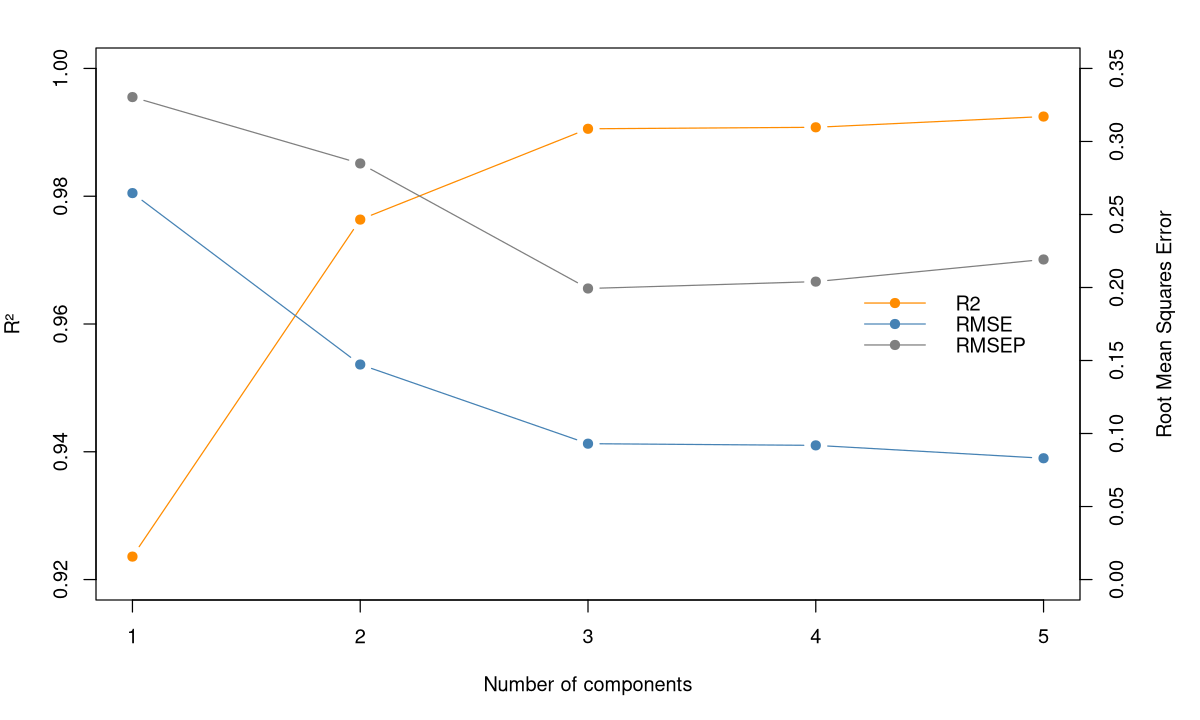

In [22]:
# Reproduction de la Fig. 5 (deux axes : R² à gauche, erreurs à droite)
par(mar = c(5, 4, 2, 5))
plot(fig5$ncomp, fig5$R2, type = "b", pch = 19, col = "darkorange", ylim = c(0.92, 1),
     xlab = "Number of components", ylab = "R²")
par(new = TRUE)
plot(fig5$ncomp, fig5$RMSE, type = "b", pch = 19, col = "steelblue", ylim = c(0, 0.35),
     axes = FALSE, xlab = "", ylab = "")
lines(fig5$ncomp, fig5$RMSEP, type = "b", pch = 19, col = "grey50")
axis(4); mtext("Root Mean Squares Error", side = 4, line = 3)
legend("right", legend = c("R2", "RMSE", "RMSEP"), col = c("darkorange", "steelblue", "grey50"),
       lty = 1, pch = 19, bty = "n")

Le RMSEP de validation croisée est **minimal à 3 variables latentes** (0.199) : c'est le choix du syllabus. Au-delà, le R² et le RMSE de calibration continuent de s'améliorer légèrement, mais l'erreur de prédiction **remonte** : c'est le surapprentissage (cf. partie 1, Fig. 2).

### 4.5.2 La statistique Q²

Autre critère proposé par le syllabus : la statistique **Q²**, qui mesure le gain de **pouvoir prédictif** apporté par la $h$-ième variable latente :

$$Q^2_h = 1 - \frac{PRESS_h}{RSS_{h-1}}$$

- $PRESS_h$ (*Predicted Residual Error Sum of Squares*) : somme des carrés des erreurs de prédiction **en validation croisée** du modèle à $h$ composantes ;
- $RSS_{h-1} = \sum_{i=1}^n (y_i - \hat y_{(h-1),i})^2$ : somme des carrés des résidus **de calibration** du modèle à $h-1$ composantes. Pour $h = 1$, le « modèle à 0 composante » est la moyenne : $RSS_0 = \sum (y_i - \bar y)^2 = n - 1$ puisque y est standardisé (ici $11$).

**Règle** : on garde la composante $h$ tant que $Q^2_h \ge 1 - 0.95^2 = 0.0975$ (*LimQ²*). Autrement dit, la nouvelle composante doit réduire l'erreur d'au moins 5 % en racine.

> **Attention** : dans cette définition (Tenenhaus, logiciel SIMCA), $PRESS_h$ est calculé en gardant **fixes** les $h-1$ premières composantes (calculées sur toutes les données) et en ne validant **que la h-ième** : à chaque observation retirée, on recalcule $w_h$ sur les résidus des autres observations et on prédit le résidu de l'observation retirée. Ce n'est pas le PRESS « classique » du modèle complet que renvoie `RMSEP()`.

In [23]:
# Q² à la Tenenhaus : leave-one-out sur la h-ième composante uniquement
q2_pls1 <- function(Xs, ys, H) {
  n <- nrow(Xs); E <- Xs; f <- ys
  rss_prev <- sum(ys^2)                         # RSS_0 = n - 1 (y standardisé)
  res <- NULL
  for (h in 1:H) {
    pred <- numeric(n)
    for (i in 1:n) {                            # on retire l'observation i
      w  <- crossprod(E[-i, ], f[-i]); w <- w / sqrt(sum(w^2))
      th <- E[-i, ] %*% w
      ch <- sum(f[-i] * th) / sum(th^2)
      pred[i] <- ch * (E[i, , drop = FALSE] %*% w)   # prédiction du résidu de i
    }
    press <- sum((f - pred)^2)
    res <- rbind(res, c(h = h, PRESS = press, RSS = rss_prev, Q2 = 1 - press / rss_prev))
    # composante h calculée sur toutes les données, puis déflation
    w  <- crossprod(E, f); w <- w / sqrt(sum(w^2)); th <- E %*% w
    ph <- crossprod(E, th) / sum(th^2); ch <- sum(f * th) / sum(th^2)
    E  <- E - th %*% t(ph); f <- f - ch * th
    rss_prev <- sum(f^2)                        # RSS_h (calibration)
  }
  data.frame(res, LimQ2 = 1 - 0.95^2)
}
kable(q2_pls1(Xs, ys, H = 6), digits = 4, align = "c")



| h | PRESS  |   RSS   |   Q2    | LimQ2  |
|:-:|:------:|:-------:|:-------:|:------:|
| 1 | 1.1368 | 11.0000 | 0.8967  | 0.0975 |
| 2 | 0.6706 | 0.8405  | 0.2021  | 0.0975 |
| 3 | 0.1895 | 0.2602  | 0.2720  | 0.0975 |
| 4 | 0.1390 | 0.1039  | -0.3376 | 0.0975 |
| 5 | 0.0907 | 0.1013  | 0.1051  | 0.0975 |
| 6 | 0.0884 | 0.0828  | -0.0679 | 0.0975 |

Comparaison avec la **Table 9** du syllabus :

| h | PRESS (syllabus) | PRESS (ici) | RSS (syllabus = ici) | Q² (syllabus) | Q² (ici) |
|---|---|---|---|---|---|
| 1 | 1.1409 | 1.1368 | 11.0000 | 0.8963 | 0.8967 |
| 2 | 0.6775 | 0.6706 | 0.8405 | 0.1939 | 0.2021 |
| 3 | 0.1931 | 0.1895 | 0.2602 | 0.2579 | 0.2720 |
| 4 | 0.1444 | 0.1390 | 0.1039 | **-0.3895** | **-0.3376** |
| 5 | 0.0901 | 0.0907 | 0.1013 | 0.1104 | 0.1051 |

Les RSS sont identiques ; les PRESS sont très proches mais pas égaux. La différence vient du **découpage de la validation croisée** : SIMCA, qui a produit la Table 9, utilise par défaut 7 groupes et non le leave-one-out. La **décision est la même** : $Q^2_4 < 0.0975$, on s'arrête à **3 variables latentes**, comme avec le RMSEP.

> **Complément** : $Q^2_5 = 0.11$ repasse au-dessus du seuil, mais on s'arrête à la **première** composante non significative : les suivantes sont construites sur des résidus de plus en plus petits et instables.

### Exercice 4.5 : PRESS du modèle complet
Le PRESS « classique » s'obtient à partir des prédictions de validation croisée du modèle complet : `pls_loo$validation$pred`.
1. Calcule ce PRESS pour 1 à 5 composantes, sur l'échelle standardisée (divise les erreurs par `sd(y)`).
2. Calcule $1 - PRESS_h / RSS_{h-1}$ avec ce PRESS. Retrouve-t-on la Table 9 ? Quelle décision prendrait-on ?

In [24]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
press_full <- colSums(((pls_loo$validation$pred[, 1, ] - y) / sd(y))^2)
round(press_full, 4)
rss <- c(n - 1, (1 - R2(pls_loo, estimate = "train")$val[1, 1, -1]) * (n - 1))
round(1 - press_full / rss[1:5], 4)
```

On obtient des valeurs très différentes (Q² négatif dès la 2e composante), car on compare l'erreur de prédiction du modèle **complet** (toutes les composantes recalculées sans l'observation) à l'erreur de **calibration** du modèle précédent, qui est beaucoup plus petite. Le Q² de la Table 9 n'a de sens qu'avec le PRESS « composante par composante » de la fonction `q2_pls1()`. Avec le PRESS complet, la bonne façon de choisir est de comparer directement les RMSEP (section 4.5.1).

</details>

---
## 4.6 Détection des valeurs anormales : le T² de Hotelling

Les observations atypiques peuvent être détectées avec le **T² de Hotelling** (syllabus §3.3). Pour l'observation $i$ et un modèle à $H$ composantes :

$$T_i^2 = \frac{n}{n-1}\sum_{h=1}^{H} \frac{t_{hi}^2}{s_h^2}$$

où $s_h^2$ est la variance (division par $n-1$) de la composante $t_h$. C'est une distance au centre du nuage dans l'espace des variables latentes, chaque direction étant pondérée par sa variance (une distance de **Mahalanobis**, cf. partie 2).

La statistique $\frac{n(n-H)}{H(n^2-1)}\,T_i^2$ suit une loi de **Fisher-Snedecor** à $H$ et $n-H$ degrés de liberté. Une observation est donc atypique (au seuil de 5 %) si :

$$T_i^2 \ge \frac{H(n^2-1)}{n(n-H)}\,F_{0.95}(H,\, n-H)$$

In [25]:
# T² de Hotelling pour H = 1, 2, 3 composantes
tsc <- scores(pls_oct)
T2 <- sapply(1:3, function(H) {
  th <- tsc[, 1:H, drop = FALSE]
  n / (n - 1) * rowSums(sweep(th^2, 2, apply(th, 2, var), "/"))
})
seuil <- sapply(1:3, function(H) H * (n^2 - 1) / (n * (n - H)) * qf(0.95, H, n - H))
tab10 <- rbind("Seuil T²" = seuil, T2)
colnames(tab10) <- paste0("H", 1:3); rownames(tab10)[-1] <- paste("Sample", 1:n)
kable(tab10, digits = 3, align = "c", caption = "Table 10 : T² de Hotelling et seuils")



Table: Table 10 : T² de Hotelling et seuils

|          |  H1   |  H2   |   H3   |
|:---------|:-----:|:-----:|:------:|
|Seuil T²  | 5.248 | 9.778 | 15.343 |
|Sample 1  | 1.155 | 2.197 | 4.238  |
|Sample 2  | 1.681 | 2.330 | 2.340  |
|Sample 3  | 1.491 | 2.816 | 2.841  |
|Sample 4  | 1.139 | 5.067 | 5.272  |
|Sample 5  | 0.001 | 0.074 | 7.199  |
|Sample 6  | 0.715 | 3.837 | 4.606  |
|Sample 7  | 1.333 | 1.382 | 1.428  |
|Sample 8  | 1.091 | 1.106 | 1.118  |
|Sample 9  | 1.196 | 1.230 | 1.333  |
|Sample 10 | 1.007 | 1.164 | 1.195  |
|Sample 11 | 1.183 | 1.510 | 2.378  |
|Sample 12 | 0.007 | 1.285 | 2.053  |

On retrouve exactement la **Table 10** (la ligne intitulée « T² » dans le syllabus est en fait le **seuil**) : 5.248, 9.778 et 15.343. Aucun échantillon ne dépasse son seuil : **aucun n'est aberrant**.

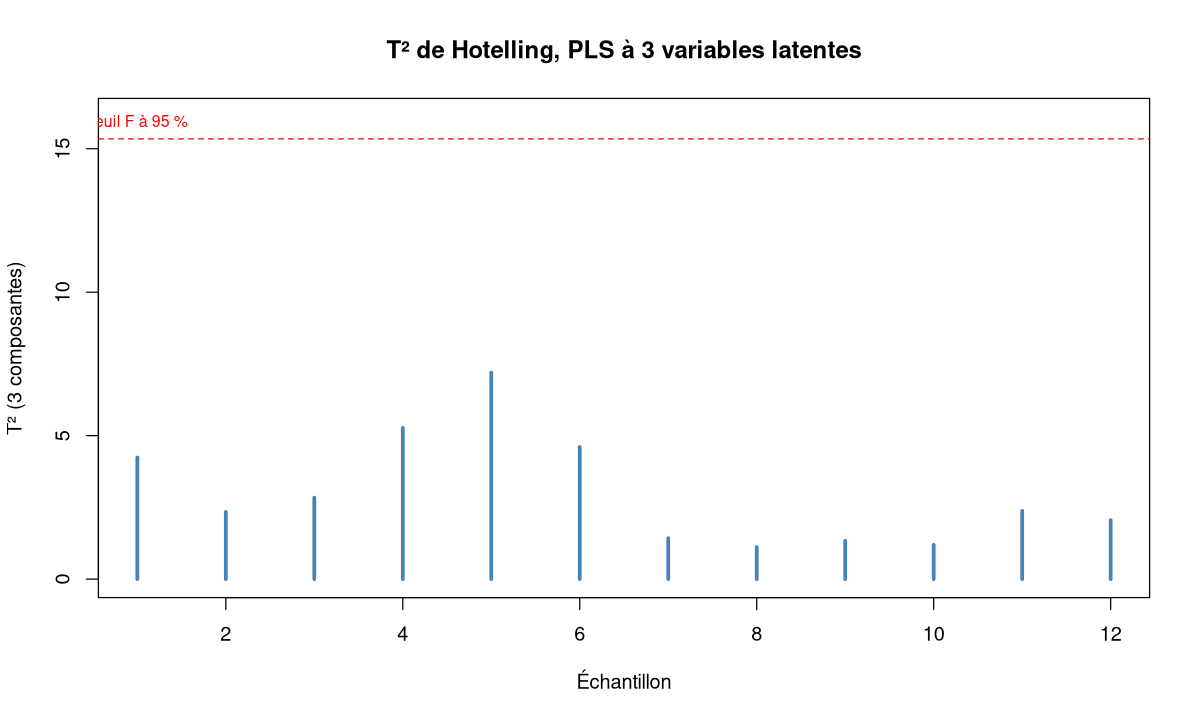

In [26]:
plot(T2[, 3], type = "h", lwd = 3, col = "steelblue", ylim = c(0, seuil[3] * 1.05),
     xlab = "Échantillon", ylab = "T² (3 composantes)", main = "T² de Hotelling, PLS à 3 variables latentes")
abline(h = seuil[3], col = "red", lty = 2)
text(1, seuil[3], "seuil F à 95 %", pos = 3, col = "red", cex = 0.8, adj = 0)

**Deuxième méthode** (syllabus) : puisque les résidus doivent suivre une loi normale, on peut aussi signaler les observations dont le **résidu** s'écarte de la moyenne de plus de **3 écarts-types** (rappel du module 1 : 99.7 % des valeurs d'une loi normale sont dans cet intervalle).

In [27]:
e <- residuals(pls_oct)[, 1, 3]                 # résidus du modèle à 3 composantes
round(e, 3)
which(abs(e - mean(e)) > 3 * sd(e))             # aucune observation hors de moyenne +/- 3 sd

1      2      3      4      5      6      7      8      9     10     11 
 1.141  0.208 -0.845  0.192  0.605 -0.575  0.403  0.525 -0.124 -0.060 -0.529 
    12 
-0.941

named integer(0)

### Exercice 4.6 : seuil plus strict
1. Recalcule les seuils du T² au niveau 99 % (`qf(0.99, ...)`).
2. Quel est l'échantillon le plus éloigné du centre avec 3 composantes ? Pourquoi à ton avis (regarde sa composition dans `octane`) ?

In [28]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
seuil99 <- sapply(1:3, function(H) H * (n^2 - 1) / (n * (n - H)) * qf(0.99, H, n - H))
round(seuil99, 3)                 # seuils plus élevés : encore moins d'échantillons signalés
which.max(T2[, 3])                # échantillon 5
octane[5, ]
```

L'échantillon 5 a la plus forte proportion de X4 (0.62) de tout le jeu de données et un score très négatif sur $t_3$ (-2.956, Table 6) : il est seul dans sa « direction ». Son T² (7.2) reste néanmoins loin du seuil (15.3) : il est atypique mais pas aberrant.

</details>

---
## 4.7 Pouvoir prédictif et explicatif des variables latentes

### 4.7.1 Pouvoir prédictif
Le **pouvoir prédictif** des variables latentes s'évalue avec le R² et le RMSE (section 4.5). Contrairement à la régression linéaire classique qui, en cas de colinéarité, impose d'**écarter** des variables (sélection, module 1), la PLS **garde toutes les variables initiales** : on peut donc toutes les interpréter.

### 4.7.2 Interprétation univariée : corrélations (Table 11)

En ACP, les corrélations entre variables et composantes sont proportionnelles aux coefficients des composantes ; ce n'est **pas** le cas en PLS. On calcule donc directement les **corrélations** entre chaque variable (X **et** y) et chaque variable latente :

In [29]:
tab11 <- cor(cbind(X, y = y), scores(pls_oct)[, 1:3])
colnames(tab11) <- c("t1", "t2", "t3")
kable(round(tab11, 2), align = "c", caption = "Table 11 : corrélations variables / variables latentes")



Table: Table 11 : corrélations variables / variables latentes

|   |  t1   |  t2   |  t3   |
|:--|:-----:|:-----:|:-----:|
|X1 | -0.90 | -0.04 | 0.32  |
|X2 | 0.06  | -0.84 | 0.52  |
|X3 | -0.91 | -0.03 | 0.31  |
|X4 | -0.71 | 0.23  | -0.62 |
|X5 | 0.59  | -0.04 | -0.57 |
|X6 | 0.92  | 0.37  | 0.12  |
|X7 | -0.82 | 0.40  | -0.39 |
|y  | 0.96  | 0.23  | 0.12  |

Lecture : $t_1$ est très corrélée à y (0.96). Elle oppose X6 (0.92, augmente l'indice d'octane) à X1, X3, X7 et X4 (corrélations négatives). $t_2$ est surtout liée à X2 (-0.84), $t_3$ à X4 et X5.

> **Complément** : on visualise souvent ces corrélations sur un **cercle des corrélations** (comme en ACP) dans le plan $(t_1, t_2)$.

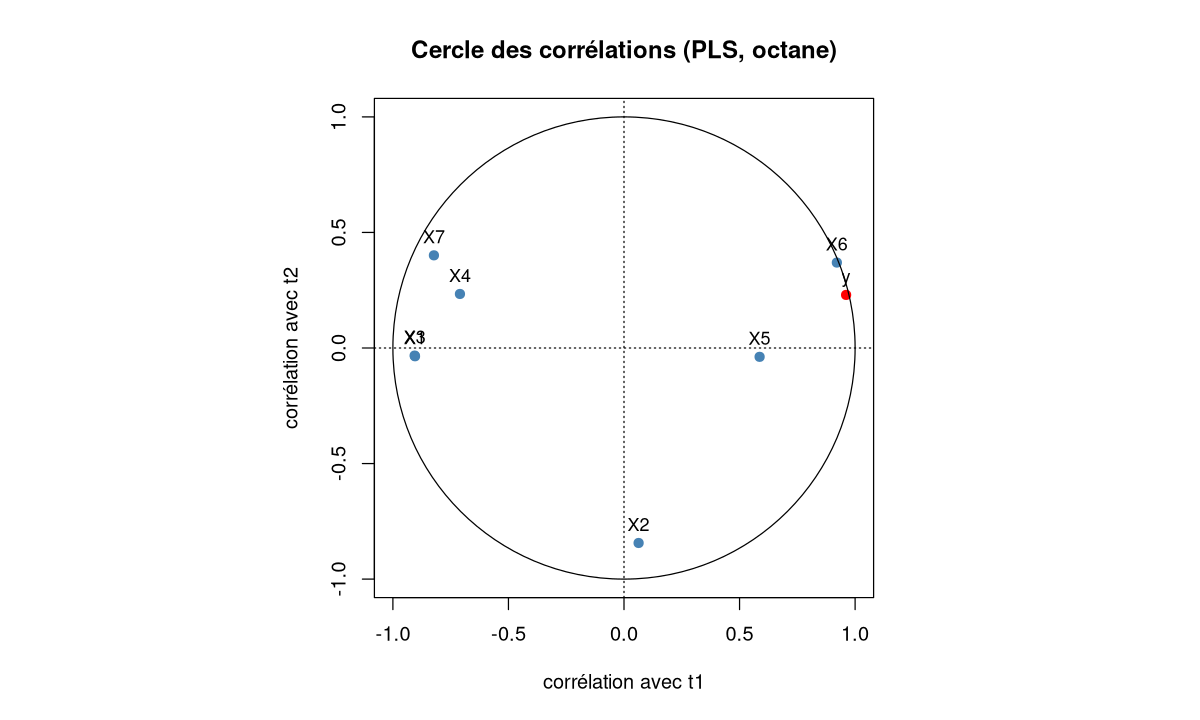

In [30]:
par(pty = "s")
plot(tab11[, 1], tab11[, 2], xlim = c(-1, 1), ylim = c(-1, 1), pch = 19,
     col = c(rep("steelblue", 7), "red"), xlab = "corrélation avec t1", ylab = "corrélation avec t2",
     main = "Cercle des corrélations (PLS, octane)")
symbols(0, 0, circles = 1, inches = FALSE, add = TRUE)
abline(h = 0, v = 0, lty = 3)
text(tab11[, 1], tab11[, 2], rownames(tab11), pos = 3, cex = 0.9)
par(pty = "m")

### 4.7.3 Interprétation multivariée : les poids w* (Table 12) et c

L'interprétation **multivariée** (combinaison des variables latentes) est plus délicate qu'en PCR, car à partir de $t_2$ les variables latentes sont construites sur des **résidus** et non sur les variables initiales. On utilise donc les poids $w^*$, qui permettent de construire **directement** les composantes à partir des x (standardisés) :

$$T = X_s\, W^* \qquad\text{avec}\qquad W^* = W\,(P'W)^{-1}$$

Les $w^*$ traduisent l'**importance de chaque variable x** dans la construction de $t_h$.

In [31]:
kable(round(pls_oct$projection[, 1:3], 2), align = "c", caption = "Table 12 : poids w*")
# Vérification : T = Xs W* (les 3 premières composantes)
all.equal(unname(Xs %*% pls_oct$projection[, 1:3]), unname(scores(pls_oct)[, 1:3]))
# W* calculé à partir de W et P (sur les 3 premières composantes)
W3 <- nip$weights[, 1:3]; P3 <- nip$loadings[, 1:3]
round(W3 %*% solve(t(P3) %*% W3), 2)



Table: Table 12 : poids w*

|   | Comp 1 | Comp 2 | Comp 3 |
|:--|:------:|:------:|:------:|
|X1 | -0.44  |  0.12  |  0.38  |
|X2 | -0.04  | -0.68  | -0.04  |
|X3 | -0.44  |  0.12  |  0.38  |
|X4 | -0.37  | -0.16  | -0.68  |
|X5 |  0.26  | -0.34  | -0.69  |
|X6 |  0.51  |  0.57  |  0.52  |
|X7 | -0.39  |  0.22  | -0.16  |

[1] TRUE

,t1,t2,t3
X1,-0.44,0.12,0.38
X2,-0.04,-0.68,-0.04
X3,-0.44,0.12,0.38
X4,-0.37,-0.16,-0.68
X5,0.26,-0.34,-0.69
X6,0.51,0.57,0.52
X7,-0.39,0.22,-0.16


Table 12 retrouvée. Pour $t_1$, $w^* = w$ (pas encore de déflation) ; ensuite les deux diffèrent.

Enfin, les poids **c** relient les variables latentes à y : $c_1 = 0.482$, $c_2 = 0.273$ et $c_3 = 0.103$ (sur y standardisé). L'équation PLS s'écrit $\hat y_s = c_1 t_1 + c_2 t_2 + c_3 t_3$ : on voit que $t_1$ porte l'essentiel de la prédiction.

### Exercice 4.7 : de w* aux coefficients
Montre que les coefficients de régression de la PLS sur les x **standardisés** valent $b = W^* c$ (avec 3 composantes). Compare à `coef(pls_s, ncomp = 3)`.

In [32]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
b_std <- pls_s$projection[, 1:3] %*% Yloadings(pls_s)[1, 1:3]
round(cbind(b_std, coef(pls_s, ncomp = 3)[, 1, 1]), 4)
```

Puisque $T = X_s W^*$ et $\hat y_s = T c$, on a $\hat y_s = X_s (W^* c)$ : le vecteur $W^* c$ contient les coefficients de régression sur les variables standardisées. C'est la « transformation inverse » qui ramène le modèle aux variables initiales.

</details>

---
## 4.8 PLS pénalisée et avantages de la PLS

### 4.8.1 PLS pénalisée (§3.6)
Comme pour la régression linéaire au module 1, augmenter le nombre de composantes peut **réduire la robustesse** du modèle. Dans le cadre PLS, on peut aussi introduire un facteur qui **pénalise** le nombre de composantes latentes : c'est la **Penalized Partial Least Squares**.

> **Complément** : la PLS pénalisée est implémentée par exemple dans le package R `ppls` (non installé ici et hors du cadre pratique du cours). L'idée est la même que Ridge/Lasso : ajouter une pénalité pour obtenir un modèle plus parcimonieux et plus robuste.

### 4.8.2 Avantages de la PLS (§3.7)
La régression PLS :

- s'utilise en présence d'un **grand nombre de variables colinéaires** ;
- s'applique même quand il y a **moins d'observations que de variables** ($n < p$), grâce à la réduction de dimension ;
- est **rapide**, car elle ne demande **pas d'inversion de matrice** : elle est donc utilisable sur de gros volumes de données.

> **Complément** : on voit dans `nipals_pls1()` que chaque étape ne fait que des produits matrice-vecteur et des divisions par des scalaires ($\sum t^2$). Comparé à la MCO du module 1, où il faut inverser $X'X$, impossible quand $p > n$, c'est ce qui rend la PLS utilisable sur des spectres de 1 060 points.

---
## 4.9 Application : acides gras saturés du lait (exercice dirigé)

On reprend l'exercice dirigé officiel (`PLS_PCR_fatty_acids_20201007.Rmd`, §4) : prédire la teneur en **acides gras saturés** (SAT, g/dl de lait) à partir des **1 060 points spectraux MIR**.

### 4.9.1 Données et nettoyage des outliers spectraux (rappel de la partie 2)

On refait le nettoyage de l'exercice dirigé : ACP sur les spectres standardisés, **47 composantes principales** (99 % de la variabilité spectrale), distance de Mahalanobis, **GH = D² / 47**, et on retire les échantillons avec GH ≥ 3.

In [33]:
fattyacid <- read.table(file = "../fatty_acids.csv", sep = ";", header = TRUE)
x <- fattyacid[, 5:1064]       # spectre : colonnes 5 à 1064
yfa <- fattyacid[, 2]          # SAT : 2e colonne
dim(x)

res.pca <- PCA(x, scale.unit = TRUE, ncp = 47, graph = FALSE)
coordPC <- res.pca$ind$coord
GH <- mahalanobis(coordPC, center = colMeans(coordPC), cov = cov(coordPC)) / 47
summary(GH)
newX <- x[GH < 3, ]; newy <- yfa[GH < 3]
c(conservés = length(newy), retirés = sum(GH >= 3))

[1]  485 1060

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.3825  0.6958  0.9044  0.9979  1.2003  4.1015 

conservés   retirés 
      482         3

Comme dans le Rmd : 482 échantillons conservés, 3 retirés. On construit le `data.frame` de calibration avec des noms de colonnes simples (`SPEC1` … `SPEC1060`), ce qui simplifie l'écriture de la formule `SAT ~ .`.

In [34]:
calibration <- data.frame(newy, newX)
names(calibration) <- c("SAT", paste0("SPEC", 1:1060))
dim(calibration)

[1]  482 1061

### 4.9.2 Le modèle PLS (10-fold CV)

In [35]:
set.seed(1001)   # même découpage de validation croisée que l'exercice dirigé
PLS <- plsr(SAT ~ ., data = calibration, method = "oscorespls", scale = TRUE, center = TRUE,
            validation = "CV", ncomp = 70)
PLS

Partial least squares regression, fitted with the orthogonal scores algorithm.
Cross-validated using 10 random segments.
Call:
pls::plsr(formula = SAT ~ ., ncomp = 70, data = calibration,     method = "oscorespls", scale = TRUE, center = TRUE, validation = "CV")

`summary(PLS)` affiche 70 colonnes pour chaque estimateur : on n'en montre que le début.

In [36]:
out <- capture.output(summary(PLS))
cat(out[1:16], sep = "\n")

Data: 	X dimension: 482 1060 
	Y dimension: 482 1
Fit method: oscorespls
Number of components considered: 70

VALIDATION: RMSEP
Cross-validated using 10 random segments.
       (Intercept)  1 comps  2 comps  3 comps  4 comps  5 comps  6 comps
CV          0.8544   0.3040   0.2644   0.2505   0.2293   0.2126   0.1993
adjCV       0.8544   0.3037   0.2643   0.2504   0.2288   0.2122   0.1987
       7 comps  8 comps  9 comps  10 comps  11 comps  12 comps  13 comps
CV      0.1876   0.1795   0.1705    0.1664    0.1650    0.1639    0.1623
adjCV   0.1868   0.1783   0.1692    0.1652    0.1636    0.1622    0.1603
       14 comps  15 comps  16 comps  17 comps  18 comps  19 comps  20 comps
CV       0.1592    0.1554    0.1491    0.1462    0.1435    0.1364    0.1324
adjCV    0.1568    0.1522    0.1454    0.1427    0.1399    0.1331    0.1297


### 4.9.3 Performances de calibration et de validation croisée

Comme dans le Rmd, on récupère R² et RMSE pour **tous** les estimateurs (`"all"` : calibration `train`, validation croisée `CV`, et `adjCV` pour le RMSEP) et on les trace. Le Rmd utilise `ggplot2` après avoir « fondu » le tableau 3D avec `melt()` :

[1]  2  1 71

,estimate,response,model,value
,<fct>,<fct>,<fct>,<dbl>
1,train,SAT,(Intercept),0.000000000
2,CV,SAT,(Intercept),-0.004162326
3,train,SAT,1 comps,0.876746356


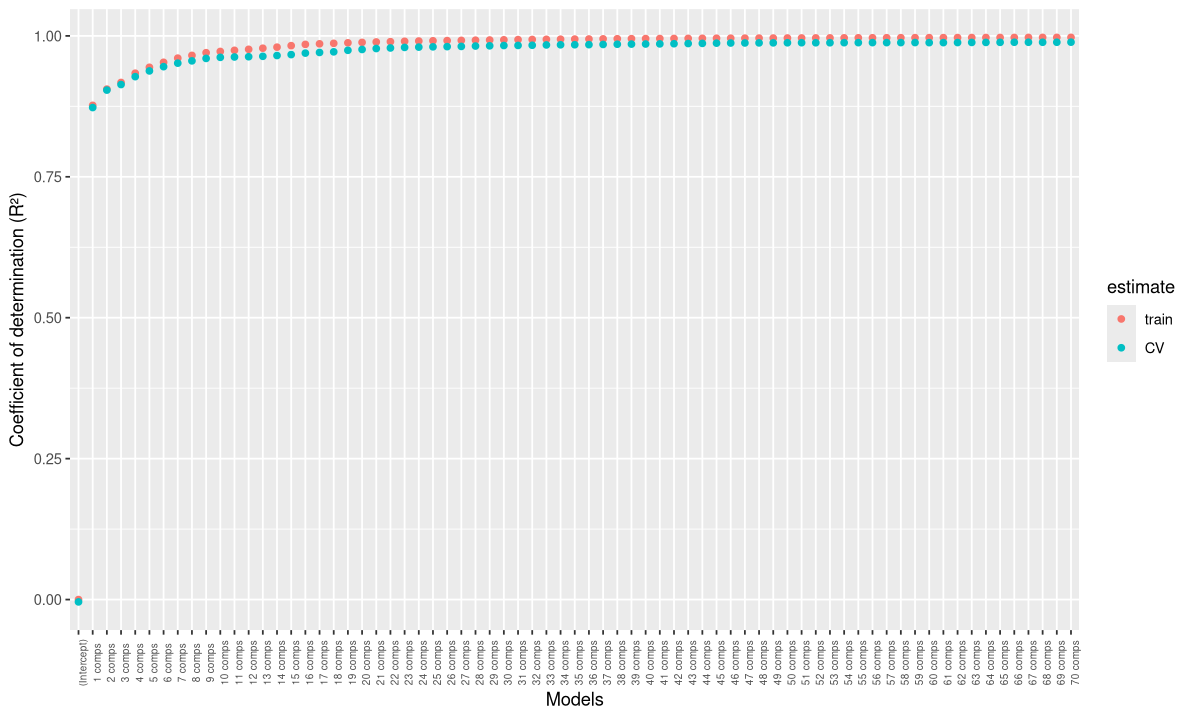

In [37]:
Rsquare <- R2(PLS, "all")
RMSEP_pls <- RMSEP(PLS, "all")
dim(Rsquare$val)                 # [estimateur, réponse, modèle] : 2 x 1 x 71
melted_R2 <- melt(Rsquare$val)   # tableau long : une ligne par (estimateur, modèle)
head(melted_R2, 3)
ggplot(melted_R2, aes(x = model, y = value, col = estimate)) + geom_point() +
  xlab("Models") + ylab("Coefficient of determination (R²)") +
  theme(axis.text.x = element_text(size = 6, angle = 90))

La même chose en base R, plus simple, avec `validationplot()` (cf. partie 3) :

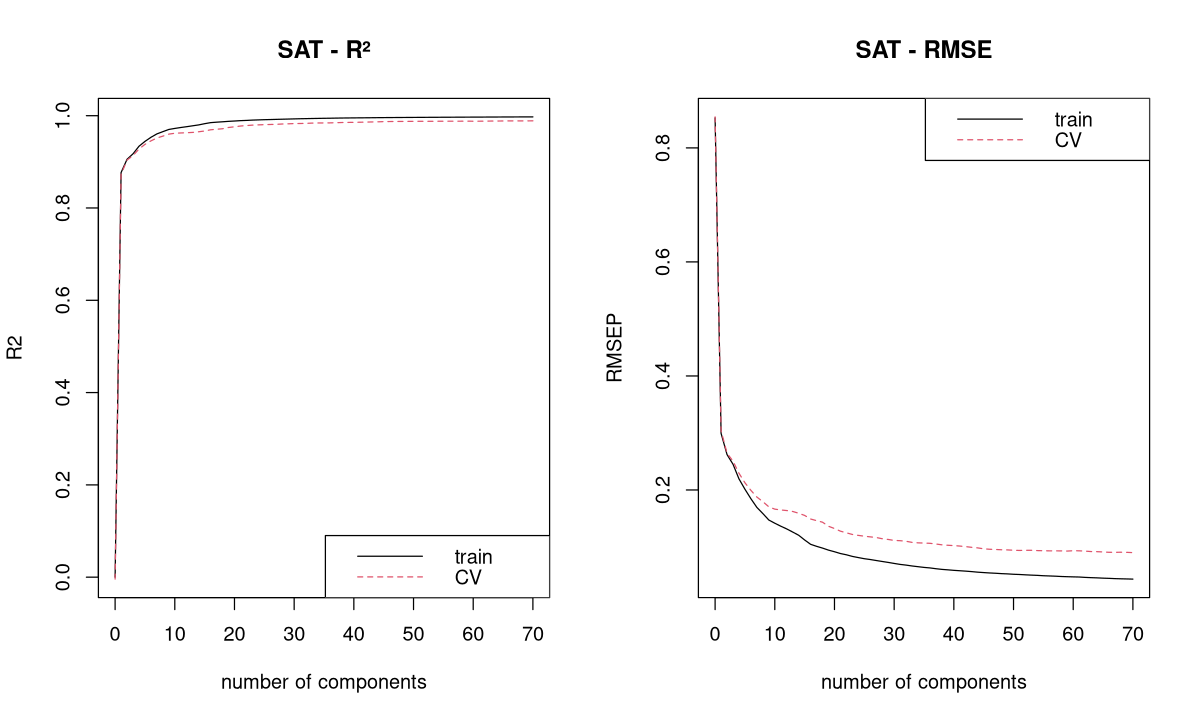

In [38]:
par(mfrow = c(1, 2))
validationplot(PLS, val.type = "R2", estimate = c("train", "CV"), legendpos = "bottomright",
               main = "SAT - R²")
validationplot(PLS, val.type = "RMSEP", estimate = c("train", "CV"), legendpos = "topright",
               main = "SAT - RMSE")
par(mfrow = c(1, 1))

On observe le même phénomène que pour la PCR : l'erreur de calibration diminue sans cesse, alors que l'écart entre calibration et validation croisée **grandit** avec le nombre de composantes (surapprentissage).

### 4.9.4 Choisir le nombre de variables latentes

L'exercice dirigé propose trois critères (déjà vus pour la PCR) :

- le **RMSEP de validation croisée le plus bas**, souvent atteint pour un très grand nombre de composantes ;
- la **plus petite différence calibration / validation croisée** (« *robustness diff* ») : plus elle est faible, plus le modèle est robuste ;
- le **plus petit gain** de validation croisée entre deux modèles consécutifs (« *accuracy diff* ») : si ajouter une composante n'apporte presque rien, on garde le modèle le plus parcimonieux.

In [39]:
# Tableau de l'exercice dirigé (écrit de façon vectorisée)
r2cal <- Rsquare$val[1, 1, ]; r2cv <- Rsquare$val[2, 1, ]
results <- data.frame(R2_calib = r2cal * 100, R2_valid = r2cv * 100,
                      RMSEP_calib = RMSEP_pls$val[1, 1, ], RMSEP_valid = RMSEP_pls$val[2, 1, ],
                      "Robustness diff" = r2cal - r2cv,
                      "Accuracy diff" = c(0, diff(r2cv)), check.names = FALSE)
kable(results[1:20, ], digits = 3, align = "c")



|            | R2_calib | R2_valid | RMSEP_calib | RMSEP_valid | Robustness diff | Accuracy diff |
|:-----------|:--------:|:--------:|:-----------:|:-----------:|:---------------:|:-------------:|
|(Intercept) |  0.000   |  -0.416  |    0.853    |    0.854    |      0.004      |     0.000     |
|1 comps     |  87.675  |  87.284  |    0.299    |    0.304    |      0.004      |     0.877     |
|2 comps     |  90.555  |  90.379  |    0.262    |    0.264    |      0.002      |     0.031     |
|3 comps     |  91.734  |  91.368  |    0.245    |    0.250    |      0.004      |     0.010     |
|4 comps     |  93.378  |  92.766  |    0.219    |    0.229    |      0.006      |     0.014     |
|5 comps     |  94.428  |  93.783  |    0.201    |    0.213    |      0.006      |     0.010     |
|6 comps     |  95.312  |  94.537  |    0.185    |    0.199    |      0.008      |     0.008     |
|7 comps     |  96.052  |  95.161  |    0.169    |    0.188    |      0.009      |     0.006     |
|8 comps

L'exercice dirigé retient **11 variables latentes** : à partir de la 12e, le gain en R² de validation croisée (« accuracy diff ») devient très faible, et l'écart calibration / validation reste petit. Avec 11 variables latentes : R²cv ≈ 96.3 % et RMSEcv ≈ 0.165 g/dl.

Le script `pls_fatty_acids.R` propose des critères automatiques :

In [40]:
rmse_cv <- RMSEP(PLS, estimate = "CV")$val[1, 1, -1]
c(min_RMSEcv = unname(which.min(rmse_cv)),              # minimum absolu
  onesigma = selectNcomp(PLS, method = "onesigma"))     # plus parcimonieux à 1 écart-type près

min_RMSEcv   onesigma 
        70         50

> **Fonction R** : `selectNcomp(object, method = c("randomization", "onesigma"), nperm = 999, alpha = 0.01, ncomp = object$ncomp, plot = FALSE, ...)`
>
> - `"onesigma"` : plus petit nombre de composantes dont le RMSEP de CV est à moins d'**un écart-type** du minimum (même idée que `lambda.1se` de `cv.glmnet`) ;
> - `"randomization"` : test de permutation : la composante suivante améliore-t-elle **significativement** la prédiction ?
>
> Nécessite un modèle ajusté avec `validation = "CV"` ou `"LOO"`. Renvoie un entier (nombre de composantes conseillé).

Le minimum absolu est atteint à **70 composantes**, c'est-à-dire au **maximum testé** : sur ce jeu de 482 spectres, l'erreur de validation croisée continue de baisser très lentement, et `onesigma` propose encore **50** composantes. Le RMSEP minimal n'est donc pas un bon critère ici (le Rmd le dit : « *unfortunately, this reaches often for a very large number of components* »). L'exercice dirigé raisonne donc en termes de **gain marginal** et retient un modèle beaucoup plus parcimonieux (11). On vérifiera en partie 5, sur un jeu de **validation externe**, si ce choix généralise bien.

### 4.9.5 Performances du modèle retenu

In [41]:
nLV <- 11
r2_cal <- R2(PLS, estimate = "train")$val[1, 1, nLV + 1]   # +1 : la 1re position est l'intercept
r2_cv  <- R2(PLS, estimate = "CV")$val[1, 1, nLV + 1]
rmse_cal <- RMSEP(PLS, estimate = "train")$val[1, 1, nLV + 1]
rmse_cv11 <- RMSEP(PLS, estimate = "CV")$val[1, 1, nLV + 1]
round(c(nLV = nLV, R2_cal = r2_cal, RMSE_cal = rmse_cal, R2_cv = r2_cv, RMSE_cv = rmse_cv11,
        RPD_cv = sd(newy) / rmse_cv11), 4)

nLV   R2_cal RMSE_cal    R2_cv  RMSE_cv   RPD_cv 
 11.0000   0.9744   0.1365   0.9626   0.1650   5.1736

> **Définition** : le **RPD** (*Ratio of Performance to Deviation*) $= \sigma_y / RMSE$ compare l'erreur du modèle à la dispersion naturelle de y. Plus il est grand, mieux c'est (en spectroscopie, on considère souvent qu'un RPD > 3 permet une prédiction quantitative fiable). Il n'est pas dans le syllabus mais est utilisé dans les scripts du module.

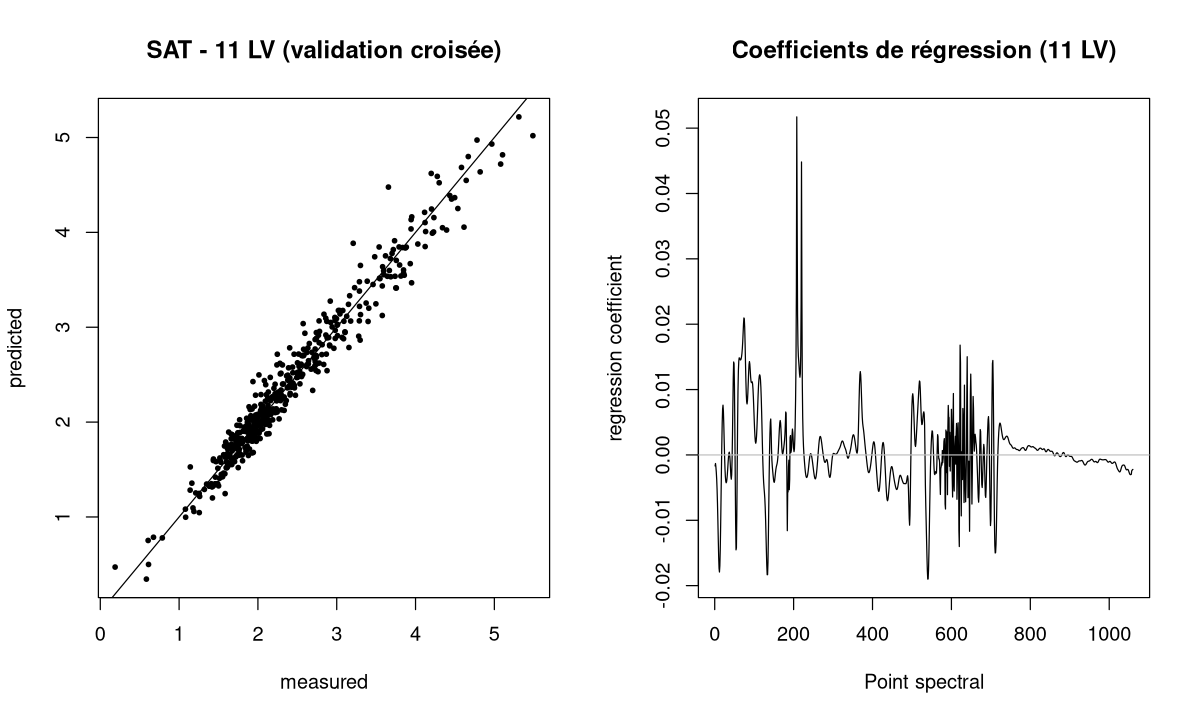

In [42]:
par(mfrow = c(1, 2))
predplot(PLS, ncomp = nLV, which = "validation", line = TRUE, pch = 19, cex = 0.5,
         main = paste("SAT -", nLV, "LV (validation croisée)"))
coefplot(PLS, ncomp = nLV, main = "Coefficients de régression (11 LV)",
         xlab = "Point spectral")
par(mfrow = c(1, 1))

Le graphe des coefficients montre **quels points spectraux** portent l'information sur SAT. Contrairement au Lasso (module 1), la PLS donne un coefficient à **tous** les points ; les zones de grands coefficients correspondent aux bandes d'absorption utiles (et parfois à des zones bruitées, cf. partie 5).

### 4.9.6 Variante du script : une colonne-matrice

Le script `pls_fatty_acids.R` range les 1 060 points spectraux dans **une seule colonne-matrice** du `data.frame`, ce qui évite de renommer 1 060 colonnes :

In [43]:
dat <- data.frame(SAT = newy)
dat$spectra <- as.matrix(newX)   # une colonne qui contient une matrice 482 x 1060
dim(dat$spectra)
pls_mat <- plsr(SAT ~ spectra, data = dat, ncomp = nLV, scale = TRUE, method = "oscorespls")
all.equal(unname(fitted(pls_mat)[, 1, nLV]), unname(fitted(PLS)[, 1, nLV]))   # même modèle

[1]  482 1060

[1] TRUE

> **Attention** : le script nettoie avec `GH <= 3` et le Rmd avec `GH < 3` : c'est équivalent ici (aucun GH n'est exactement égal à 3). Avec la colonne-matrice, de nouvelles données à prédire doivent avoir **la même structure** (`newdata = data.frame(spectra = I(as.matrix(...)))`).

### Exercice 4.8 : RPD et lecture du tableau
À partir du tableau `results` :
1. Quel est le RMSE de validation croisée avec 5, 11 et 20 variables latentes ?
2. Calcule le RPD de validation croisée pour ces trois modèles.
3. Pour quel nombre de variables latentes le RPD dépasse-t-il 5 pour la première fois ?

In [44]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
k <- c(5, 11, 20)
rmse_k <- results$RMSEP_valid[k + 1]          # +1 : la 1re ligne est l'intercept
round(rbind(RMSE_cv = rmse_k, RPD_cv = sd(newy) / rmse_k), 3)
rpd_all <- sd(newy) / results$RMSEP_valid[-1]
which(rpd_all > 5)[1]
```

Attention au décalage : dans les objets `R2()` / `RMSEP()` et dans `results`, la **1re position** correspond au modèle à 0 composante (intercept seul).

</details>

---
## 4.10 PCR vs PLS sur les acides gras

L'exercice dirigé conclut : « *Based on the estimated PCR and PLS performances for the same number of components, we can conclude that PLS provides better results.* » Vérifions-le en ajustant la PCR (partie 3) avec le même découpage de validation croisée.

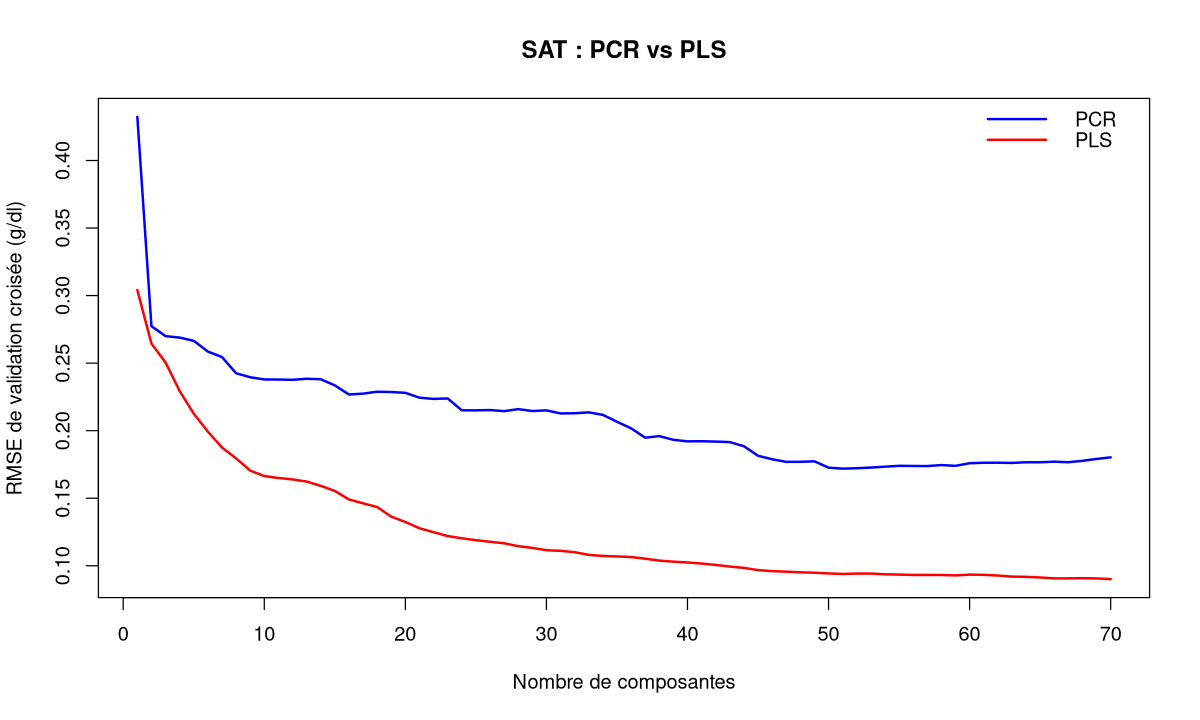

In [45]:
set.seed(1001)
PCR <- pcr(SAT ~ ., data = calibration, scale = TRUE, center = TRUE, validation = "CV", ncomp = 70)
rmse_pcr <- RMSEP(PCR, estimate = "CV")$val[1, 1, -1]
rmse_pls <- RMSEP(PLS, estimate = "CV")$val[1, 1, -1]
plot(1:70, rmse_pcr, type = "l", col = "blue", lwd = 2, ylim = range(rmse_pcr, rmse_pls),
     xlab = "Nombre de composantes", ylab = "RMSE de validation croisée (g/dl)",
     main = "SAT : PCR vs PLS")
lines(1:70, rmse_pls, col = "red", lwd = 2)
legend("topright", legend = c("PCR", "PLS"), col = c("blue", "red"), lwd = 2, bty = "n")

In [46]:
kable(data.frame(ncomp = c(5, 10, 11, 20),
                 RMSEcv_PCR = rmse_pcr[c(5, 10, 11, 20)],
                 RMSEcv_PLS = rmse_pls[c(5, 10, 11, 20)]), digits = 3, align = "c")



|         | ncomp | RMSEcv_PCR | RMSEcv_PLS |
|:--------|:-----:|:----------:|:----------:|
|5 comps  |   5   |   0.267    |   0.213    |
|10 comps |  10   |   0.238    |   0.166    |
|11 comps |  11   |   0.238    |   0.165    |
|20 comps |  20   |   0.228    |   0.132    |

À nombre de composantes égal, la PLS a toujours une erreur de validation croisée **plus faible** : avec 10 composantes, 0.166 contre 0.238 g/dl pour la PCR. Pour atteindre une erreur donnée, la PLS a besoin de **beaucoup moins** de composantes, puisqu'elle les oriente vers y.

### Exercice 4.9 : combien de composantes pour la PCR ?
Combien de composantes faut-il à la PCR pour atteindre le RMSE de validation croisée de la PLS à 11 variables latentes (`rmse_pls[11]`) ? Utilise `which()`.

In [47]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
which(rmse_pcr <= rmse_pls[11])[1]
```

La PCR a besoin de bien plus de composantes (plusieurs dizaines) pour atteindre l'erreur de la PLS à 11 composantes : ses premières composantes décrivent la variabilité spectrale **la plus forte**, qui n'est pas forcément celle liée à SAT.

</details>

---
## Questions de compréhension

**Q1.** Vrai ou faux : la 1re variable latente de la PLS est la même que la 1re composante principale de la PCR.

**Q2.** Pourquoi divise-t-on les corrélations par $\sqrt{\sum R^2}$ dans NIPALS ?

**Q3.** Dans la Table 9, pourquoi s'arrête-t-on à 3 variables latentes alors que $Q^2_5 > 0.0975$ ?

**Q4.** Un échantillon a un T² supérieur au seuil de Fisher. Que faut-il faire ?

**Q5.** Quelle est la différence entre les poids $w$ et $w^*$ ?

**Q6.** Citez trois avantages de la PLS par rapport à la régression linéaire classique.

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** Faux. La 1re composante principale maximise la **variance de X** ; la 1re variable latente PLS maximise la **covariance avec y**. Sur l'octane : la PCR explique 89.69 % de y avec une composante, la PLS 92.36 %.

**Q2.** Pour **normer** le vecteur des poids ($\sum w^2 = 1$). Sans cette contrainte, multiplier les poids par une constante augmenterait la covariance à l'infini.

**Q3.** On s'arrête à la **première** composante dont le Q² passe sous la limite ($Q^2_4 = -0.39$) : la 4e composante dégrade la prédiction, les suivantes sont construites sur des résidus minuscules et instables.

**Q4.** Vérifier son origine (erreur de mesure, échantillon d'une autre population…). S'il s'agit d'une erreur, on le retire et on recalcule le modèle ; sinon, c'est peut-être le signe que le jeu de calibration ne couvre pas assez la variabilité (cf. distance GH, partie 2).

**Q5.** $w_h$ s'applique aux **résidus** $E_{h-1}$ (après déflation) ; $w^*_h$ s'applique **directement aux x d'origine** standardisés ($T = X_s W^*$). Pour interpréter les variables latentes en fonction des variables initiales, on utilise $w^*$.

**Q6.** Elle fonctionne avec beaucoup de variables **colinéaires**, quand $n < p$, et elle est **rapide** (pas d'inversion de matrice). Elle garde en plus toutes les variables, ce qui permet de les interpréter toutes.

</details>

---
## Récapitulatif

- La **PLS** réduit la dimension de X comme la PCR, mais construit ses **variables latentes** en maximisant la **covariance avec y** : elle atteint la même précision avec **moins de composantes**.
- **NIPALS (PLS1)** : 1) standardiser X et y ; 2) poids $w = R / \sqrt{\sum R^2}$, scores $t = X_s w$, régressions de X ($p$) et de y ($c$) sur $t$ : $\beta = (t't)^{-1}t'D_s$ ; 3) déflation (résidus) et on recommence.
- Nombre de variables latentes : **validation croisée** (RMSEP minimal ou gain marginal) ou **Q²** ($Q^2_h = 1 - PRESS_h/RSS_{h-1} \ge 0.0975$).
- Valeurs anormales : **T² de Hotelling** avec un seuil de Fisher $F_{0.95}(H, n-H)$, ou résidus hors de la moyenne ± 3 sd.
- Interprétation : corrélations variables / composantes (univariée), poids $w^*$ (multivariée), poids $c$ (lien avec y).
- Sur les acides gras : 11 variables latentes, R²cv ≈ 0.96, RMSEcv ≈ 0.165 g/dl ; à nombre de composantes égal, la PLS bat la PCR.

| Fonction | Rôle |
|---|---|
| `scale()` | standardiser X et y |
| `plsr(y ~ ., data, ncomp, scale, validation, method)` | ajuster une PLS (avec validation croisée) |
| `scores()`, `loadings()`, `loading.weights()`, `$projection`, `Yloadings()` | $T$, $P$, $W$, $W^*$, $c$ |
| `summary()`, `explvar()` | variance expliquée de X (et de y avec `summary`) |
| `R2(mod, "all")`, `RMSEP(mod, "all")` | performances calibration / validation croisée (tableaux `[estimateur, réponse, modèle]`) |
| `validationplot()`, `predplot()`, `coefplot()` | graphiques de validation, prédits vs observés, coefficients |
| `selectNcomp(mod, "onesigma")` | choix automatique du nombre de composantes |
| `coef(mod, ncomp, intercept = TRUE)`, `predict(mod, newdata, ncomp)` | équation finale et prédictions |
| `qf(0.95, H, n - H)` | quantile de Fisher pour le seuil du T² |
| `melt()` (reshape2) + `ggplot()` | graphiques de l'exercice dirigé |

**Suite** : `05_Comparaison_des_modeles_et_validation_externe.ipynb` compare PCR, PLS et régressions pénalisées en **validation croisée** puis sur un **jeu de validation externe** indépendant.